# 01 · Know your study area: getting the open data

**For:** anyone who needs to understand a place from open data, whatever their discipline: sociology,
anthropology, gender studies, history, literature, labour studies, urban studies, public health. No GIS
background is assumed. The example is **Quetta**, Balochistan; change `PLACE` below to study your own area.

**You will collect:**

| Layer | Source | Licence |
|---|---|---|
| Boundary | OpenStreetMap via Nominatim | ODbL |
| Streets as a network | OpenStreetMap via OSMnx (Overpass) | ODbL |
| Buildings and places, OSM | Geofabrik daily extract of OpenStreetMap | ODbL |
| Buildings | OpenStreetMap, and Overture Maps (which merges OSM, Microsoft and Google footprints) | ODbL / CDLA-Permissive |
| Places people go: schools, clinics, mosques, markets, bus stops, workplaces | OpenStreetMap (Geofabrik extract), and Overture places (Meta, Microsoft) | ODbL / CDLA-Permissive |
| Population per 100 m cell | WorldPop 2020, constrained, UN-adjusted | CC BY 4.0 |

Everything is saved to `data/` the first time, so later notebooks (and re-runs) do not download again.

In [1]:
import os, sys, warnings
from pathlib import Path
if (Path(sys.prefix) / "Library/share/gdal").exists():        # Windows conda: tell GDAL where its settings are, before importing it
    os.environ["GDAL_DATA"] = str(Path(sys.prefix) / "Library/share/gdal")
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd
import osmnx as ox
import matplotlib.pyplot as plt

PLACE = "Quetta, Balochistan, Pakistan"
CRS = 32642                    # UTM zone 42N: metres, right for Quetta. Find yours at https://epsg.io
DATA = Path("data"); DATA.mkdir(exist_ok=True)
ox.settings.use_cache = True; ox.settings.cache_folder = str(DATA / "osm_cache")
ox.settings.requests_timeout = 600     # large areas take a while; if the main server is busy, try a mirror:
# ox.settings.overpass_url = "https://overpass.kumi.systems/api"

def cached(name, make):
    """Load data/<name>.gpkg if it exists, otherwise make it, save it and return it."""
    f = DATA / f"{name}.gpkg"
    if f.exists():
        return gpd.read_file(f)
    g = make(); g.to_file(f); return g

## 1. The boundary
Nominatim (OpenStreetMap's place search) returns the administrative area matching the name: here Quetta City
Tehsil. Check what you got: a name can match a district, a city or a neighbourhood.

In [2]:
area = cached("boundary", lambda: ox.geocode_to_gdf(PLACE)[["display_name", "geometry"]])
print(area.display_name.iloc[0]); print(f"{area.to_crs(CRS).area.iloc[0] / 1e6:.0f} km²")
poly = area.geometry.iloc[0]

Quetta City Tehsil, Quetta District, Quetta Division, Balochistan, Pakistan
432 km²


## 2. Streets as a network
A street network is a *graph*: junctions are nodes, street segments are edges. Treating streets this way lets us
ask how far places are *along streets*, not as the crow flies. `network_type="walk"` keeps paths people can walk.

In [3]:
gfile = DATA / "walk.graphml"
G = ox.load_graphml(gfile) if gfile.exists() else ox.graph_from_polygon(poly, network_type="walk")
if not gfile.exists(): ox.save_graphml(G, gfile)
nodes, edges = ox.graph_to_gdfs(G)
print(f"{len(nodes):,} junctions, {len(edges):,} street segments, {edges.to_crs(CRS).length.sum() / 2e3:,.0f} km of walkable street")
edges.highway.astype(str).value_counts().head(8)

18,491 junctions, 48,140 street segments, 2,283 km of walkable street


highway
residential     32036
service          6982
unclassified     2224
tertiary         2100
primary          1844
secondary        1822
trunk             488
track             146
Name: count, dtype: int64

## 3. Buildings, from two sources
OpenStreetMap buildings are traced by volunteers; coverage is uneven across the world. Overture Maps adds
machine-detected footprints (Microsoft, Google) where OSM has none. Comparing them shows where each is complete.

In [4]:
# OpenStreetMap two ways. *Overpass* (what OSMnx uses) queries the live database: ideal for small areas, but its
# public servers are often busy and refuse large requests. A *Geofabrik extract* is a daily snapshot of a whole
# country in one file (Pakistan: about 150 MB), read locally with GDAL: slower to start, but it always works.
import sys, re, urllib.request
PBF = DATA / "pakistan-latest.osm.pbf"
if not PBF.exists():
    urllib.request.urlretrieve("https://download.geofabrik.de/asia/pakistan/pakistan-latest.osm.pbf", PBF)
BBOX = tuple(area.total_bounds)

def osm_layer(layer):
    """One layer of the extract inside the area, with every tag in other_tags spread into its own column."""
    g = gpd.read_file(PBF, layer=layer, bbox=BBOX)
    tags = g.other_tags.fillna("").map(lambda t: dict(re.findall(r'"([^"]+)"=>"([^"]*)"', t)))
    extra = pd.DataFrame(list(tags), index=g.index)
    g = pd.concat([g.drop(columns="other_tags"), extra[[c for c in extra.columns if c not in g.columns]]], axis=1)
    return gpd.GeoDataFrame(g, geometry="geometry", crs=4326).loc[lambda d: d.intersects(poly)]

osm_b = cached("buildings_osm", lambda: osm_layer("multipolygons").loc[lambda d: d.building.notna(),
               lambda d: [c for c in ["osm_id", "osm_way_id", "building", "building:levels", "name", "geometry"] if c in d.columns]])

def overture_buildings():
    """Overture buildings in the bounding box (one query to Overture's public cloud release), clipped to the area."""
    import overturemaps
    t = overturemaps.record_batch_reader("building", tuple(area.total_bounds)).read_all()
    g = gpd.GeoDataFrame.from_arrow(t).set_crs(4326, allow_override=True)
    keep = [c for c in ["id", "height", "num_floors", "class", "geometry"] if c in g.columns]
    g = g[keep]
    g["sources"] = [str(s) for s in t.column("sources").to_pylist()] if "sources" in t.column_names else ""
    return g[g.intersects(poly)]
ov_b = cached("buildings_overture", overture_buildings)
print(f"OSM: {len(osm_b):,} buildings; Overture: {len(ov_b):,}")

OSM: 889 buildings; Overture: 254,056


In [5]:
ov_b["origin"] = np.select([ov_b.sources.str.contains("OpenStreetMap"), ov_b.sources.str.contains("Microsoft"),
                            ov_b.sources.str.contains("Google")], ["OpenStreetMap", "Microsoft ML", "Google Open Buildings"], "other")
ov_b.origin.value_counts()

origin
Google Open Buildings    162968
Microsoft ML              90199
OpenStreetMap               889
Name: count, dtype: int64

## 4. Places people go
Two sources again: OSM tags and Overture's business and venue listings (which come largely from Meta and
Microsoft). Both are sparse in Quetta; together they are a better, still incomplete, picture.

OpenStreetMap tags describe what a place is (`amenity=school`, `shop=*`, `building=mosque`). Pick tags that match
your question; here a general set. Each becomes a point (polygons are reduced to their centre).

In [6]:
COL = lambda p, k: p[k] if k in p.columns else pd.Series(index=p.index, dtype=object)

def places():
    """Points of interest (points, and areas reduced to a point) with a simple category."""
    p = pd.concat([osm_layer("points"), osm_layer("multipolygons")], ignore_index=True)
    am, sh = COL(p, "amenity"), COL(p, "shop")
    p["category"] = np.select(
        [am.isin(["school", "college", "university", "library", "kindergarten", "madrasa"]),
         am.isin(["hospital", "clinic", "doctors", "pharmacy", "dentist"]) | COL(p, "healthcare").notna(),
         am.eq("place_of_worship") | COL(p, "building").isin(["mosque", "church", "temple"]),
         sh.notna() | am.eq("marketplace"),
         COL(p, "highway").eq("bus_stop") | am.eq("bus_station") | COL(p, "public_transport").notna() | COL(p, "railway").eq("station"),
         COL(p, "landuse").eq("industrial") | COL(p, "man_made").eq("works") | COL(p, "office").notna() | COL(p, "craft").notna(),
         COL(p, "leisure").isin(["park", "playground", "sports_centre", "pitch", "stadium"]),
         COL(p, "historic").notna() | COL(p, "tourism").isin(["museum", "attraction"])],
        ["education", "health", "worship", "shops and markets", "public transport", "work", "leisure", "heritage"], "")
    p = p[p.category != ""].copy()
    p["geometry"] = p.geometry.representative_point()
    keep = [c for c in ["osm_id", "name", "name:en", "name:ur", "amenity", "shop", "religion", "category", "geometry"] if c in p.columns]
    return p[keep]
osm_poi = cached("places_osm", places)
osm_poi["source"] = "OpenStreetMap"

def overture_places():
    """Overture places (businesses and venues, mostly from Meta and Microsoft) with the same simple categories."""
    import overturemaps
    t = overturemaps.record_batch_reader("place", tuple(area.total_bounds)).read_all()
    g = gpd.GeoDataFrame.from_arrow(t.select(["id", "geometry", "confidence"])).set_crs(4326, allow_override=True)
    g["name"] = [n["primary"] if n else None for n in t.column("names").to_pylist()]
    g["kind"] = t.column("basic_category").to_pylist()
    k = g.kind.fillna("")
    rules = [("education", "school|college|universit|learning|education|library|tutor"),
             ("health", "hospital|clinic|dental|health|medical|pharmac|diagnostic|doctor|rehabilitation"),
             ("worship", "worship|religious|mosque|church|temple|shrine"),
             ("shops and markets", "store|shop|mall|market|retail|bazaar"),
             ("public transport", "bus|train|station|transport|airport"),
             ("work", "office|service|factory|industr|manufactur|business|construction|law_firm|agency"),
             ("leisure", "park|gym|sport|stadium|fitness|recreation"),
             ("heritage", "historic|museum|monument|landmark")]
    g["category"] = np.select([k.str.contains(p) for _, p in rules], [c for c, _ in rules], "other")
    return g[g.intersects(poly)]
ov_poi = cached("places_overture", overture_places)
ov_poi["source"] = "Overture"
poi = pd.concat([osm_poi, ov_poi[ov_poi.category != "other"]], ignore_index=True)
poi = gpd.GeoDataFrame(poi, geometry="geometry", crs=4326)
poi.to_file(DATA / "places.gpkg")
pd.crosstab(poi.category, poi.source, margins=True)

source,OpenStreetMap,Overture,All
category,,,
education,32,274,306
health,34,121,155
heritage,24,21,45
leisure,48,38,86
public transport,23,49,72
shops and markets,122,296,418
work,56,453,509
worship,28,22,50
All,367,1274,1641


## 5. People: population per 100 m cell
WorldPop estimates how many people live in each 100 m cell, distributing census totals to where buildings are
("constrained"). It is a model, not a count: good for comparing areas, rough for a single street.

In [7]:
import rasterio, rasterio.mask, urllib.request
pop_f = DATA / "population.tif"
if not pop_f.exists():
    url = "https://data.worldpop.org/GIS/Population/Global_2000_2020_Constrained/2020/BSGM/PAK/pak_ppp_2020_UNadj_constrained.tif"
    tmp = DATA / "pak_pop_2020.tif"
    urllib.request.urlretrieve(url, tmp)
    with rasterio.open(tmp) as src:
        arr, tr = rasterio.mask.mask(src, [poly.__geo_interface__], crop=True)
        meta = src.meta | {"height": arr.shape[1], "width": arr.shape[2], "transform": tr, "compress": "deflate"}
    with rasterio.open(pop_f, "w", **meta) as dst:
        dst.write(arr)
    tmp.unlink()
with rasterio.open(pop_f) as src:
    pop = src.read(1, masked=True); pop_tr, pop_crs = src.transform, src.crs
print(f"estimated population in the area: {pop.sum():,.0f}")

estimated population in the area: 646,850


WorldPop puts about 650,000 people in the tehsil. Census-based figures for Quetta city are well above a million.
Constrained models place people only where buildings were detected, and under-count fast-growing and informal
areas, so use these numbers for *relative* comparisons inside the city, and check totals against the census.

## 6. Look at everything together

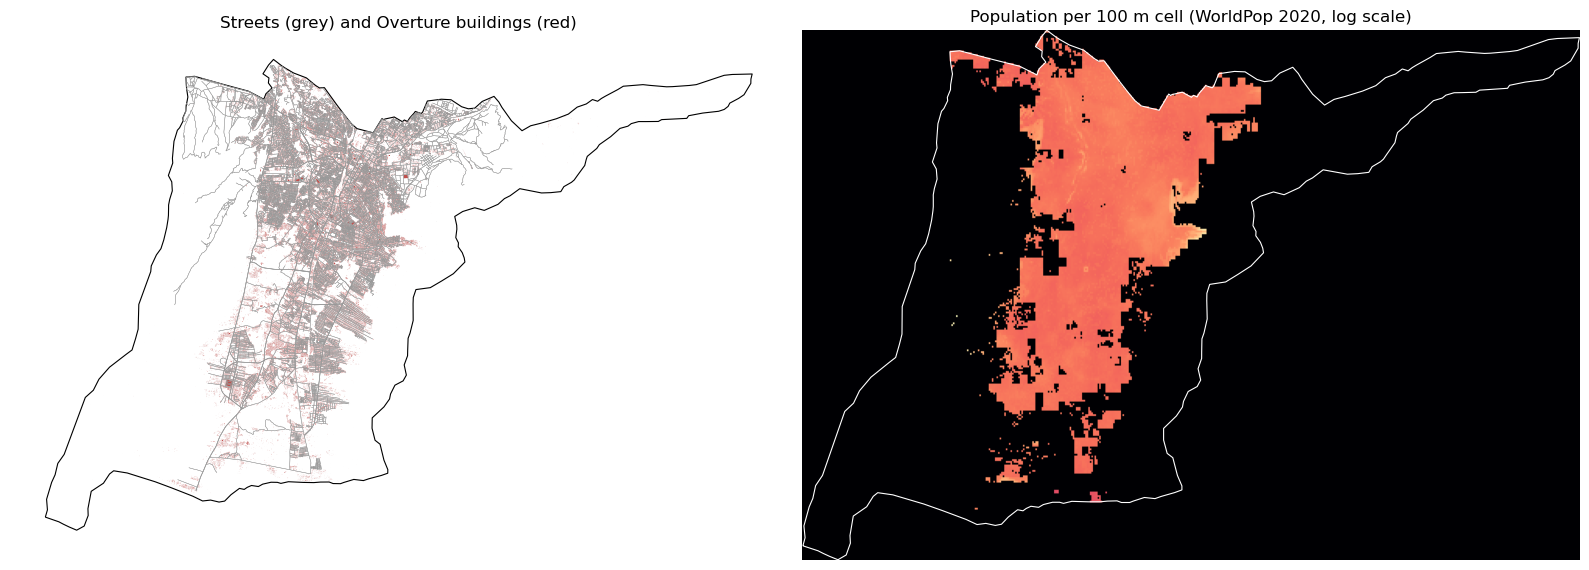

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(16, 8))
area.to_crs(CRS).boundary.plot(ax=ax[0], color="black", lw=.8)
edges.to_crs(CRS).plot(ax=ax[0], color="#999", lw=.3)
ov_b.to_crs(CRS).plot(ax=ax[0], color="#c0504d", lw=0)
ax[0].set_title("Streets (grey) and Overture buildings (red)"); ax[0].set_axis_off()
from rasterio.plot import show
show(np.log1p(pop.filled(0)), transform=pop_tr, ax=ax[1], cmap="magma")
area.boundary.plot(ax=ax[1], color="white", lw=.8)
ax[1].set_title("Population per 100 m cell (WorldPop 2020, log scale)"); ax[1].set_axis_off(); plt.tight_layout()

## 7. An interactive map you can explore
`explore()` turns any layer into a zoomable web map (Leaflet, through folium). Hover for names, click for details,
switch layers on and off at the top right. It works inside Jupyter, Colab and VS Code, and stays interactive in the
saved notebook and in this guide's web page.

In [9]:
import folium
m = area.explore(style_kwds={"fill": False, "color": "black"}, name="boundary", tiles="CartoDB positron")
colours = {"education": "blue", "health": "red", "worship": "green", "shops and markets": "orange",
           "public transport": "purple", "work": "gray", "leisure": "darkgreen", "heritage": "brown"}
for cat_, col in colours.items():
    sub = poi[poi.category == cat_]
    if len(sub):
        sub.explore(m=m, color=col, name=f"{cat_} ({len(sub)})", tooltip=[c for c in ["name", "category"] if c in sub],
                    marker_kwds={"radius": 4}, show=cat_ in ("education", "health"))
folium.LayerControl(collapsed=False).add_to(m)
m

## What the data can and cannot tell you
- **Coverage is uneven.** An empty patch on the map may mean no buildings or no mappers. Compare sources (section
  3) and look at satellite imagery before concluding.
- **Tags reflect who maps.** Places important to some groups (women's spaces, informal markets, shrines, labour
  camps) are often missing. Absence in OSM is not absence on the ground: fieldwork and local knowledge come first.
- **Population is modelled.** Use it for comparison, not counting individuals.

Next: notebook 02 combines these layers to answer questions: what is near what, who can reach what, where things
cluster.